# **Module 10: Principal Component Factor Analysis**

---

## 📌 Overview

**Principal Component Factor Analysis** (PCA — *Principal Component Analysis* / Factor Analysis) is a multivariate **unsupervised learning** technique used for **dimensionality reduction** and identifying latent structures in datasets with many correlated variables.

Its goal is to condense the information from multiple original variables into a smaller number of orthogonal **factors (or principal components)**, preserving as much of the total variance in the data as possible. This approach is widely applied to eliminate multicollinearity, build composite indices and rankings, visualize high-dimensional data, and prepare features for Machine Learning models.

---

## 🎯 Learning Objectives

By the end of this module, you will be able to:

* **Evaluate data suitability** for factor analysis using the correlation matrix, **Bartlett's test of sphericity**, and the **KMO** (*Kaiser-Meyer-Olkin*) measure.
* **Understand factor extraction** through eigenvalues, eigenvectors, and the proportion of explained variance.
* **Determine the optimal number of factors** by applying the **Kaiser Criterion** (eigenvalues $> 1$), the **Scree Plot**, and the cumulative percentage of variance explained.
* **Interpret factor loadings and communalities**, understanding how much each original variable contributes to each extracted factor.
* **Apply factor rotation techniques** (such as *Varimax*) to simplify the practical interpretation of factors.
* **Compute factor scores** to build composite rankings, synthetic indices, or use the extracted factors as input features for predictive models in Python.

---

## 🧭 Module Structure

1. **Fundamentals of Dimensionality Reduction** — Variable correlation, standardization ($Z$-score), and latent structure.
2. **Sampling Adequacy Tests** — Correlation matrix, KMO statistic, and Bartlett's Test of Sphericity.
3. **Component and Factor Extraction** — Eigenvalues, eigenvectors, explained variance, Kaiser Criterion, and Scree Plot.
4. **Factor Loadings, Communalities, and Rotation** — Interpreting factors and orthogonal rotation (*Varimax*).
5. **Factor Scores and Practical Applications** — Building composite rankings and eliminating multicollinearity.
6. **Hands-on Python** — Complete implementation using `scikit-learn`, `factor_analyzer`, `pandas`, `numpy`, `matplotlib`, and `seaborn`.

---

## 🛠️ Technical Requirements

* Prior knowledge of **Correlation** (*Module 03*), **Standardization ($Z$-Score)** (*Module 05*), and **Cluster Analysis** (*Module 09*).
* Python environment configured with: `numpy`, `pandas`, `scipy`, `scikit-learn`, `factor_analyzer`, `matplotlib`, and `seaborn`.

In [1]:
# Import libraries
import pandas as pd
import numpy as np
import math
import matplotlib.pyplot as plt
import seaborn as sns
import scipy.stats as stats
from scipy.stats import chi2

Factor analysis is an exploratory multivariate technique used when we want to study the joint behavior of metric variables and create, from the correlations among them, new variables called `factors`, which represent latent dimensions behind the original variables.

While cluster analysis (Module 09) groups observations (rows), factor analysis groups variables (columns). Its main objectives are:

* `Structural reduction:` representing many variables through a few factors with minimal information loss.
* `Building indices and rankings:` combining variables into a composite performance indicator.
* `Construct validation:` verifying whether variables meant to measure the same concept group into the same factor.
* `Orthogonal factors:` since the factors are uncorrelated with one another, they can be used in regression models without multicollinearity issues.

The most widely used extraction method—and the one covered in this module—is `principal components`.

`NOTE:` *Just as in Module 09, this technique is exploratory and static: if new observations or variables are added, the factors must be recalculated.*

## **Pearson Correlation and the Concept of a Factor**

The starting point is the correlation matrix $\rho$ among the $k$ variables:

$\rho = \begin{bmatrix} 1 & \rho_{12} & \cdots & \rho_{1k} \\ \rho_{21} & 1 & \cdots & \rho_{2k} \\ \vdots & \vdots & \ddots & \vdots \\ \rho_{k1} & \rho_{k2} & \cdots & 1 \end{bmatrix}$

Variables with high correlation (close to −1 or 1) tend to form the same factor, while variables with correlation close to 0 tend to fall into different factors.

Consider a hypothetical example with three variables, as in Figures 10.1 to 10.4 of the textbook: $X_1$ and $X_2$ are strongly correlated, while $X_3$ is unrelated to them.

In [2]:
np.random.seed(42)
n = 60

# Hypothetical scenario: X1 and X2 correlated, X3 independent
x1 = np.random.normal(5, 2, n)
x2 = 0.9 * x1 + np.random.normal(0, 0.6, n)
x3 = np.random.normal(5, 2, n)

hypothetical = pd.DataFrame({"X1": x1, "X2": x2, "X3": x3})
hypothetical.corr().round(3)

,X1,X2,X3
X1,1.000,0.948,0.111
X2,0.948,1.000,0.181
X3,0.111,0.181,1.000


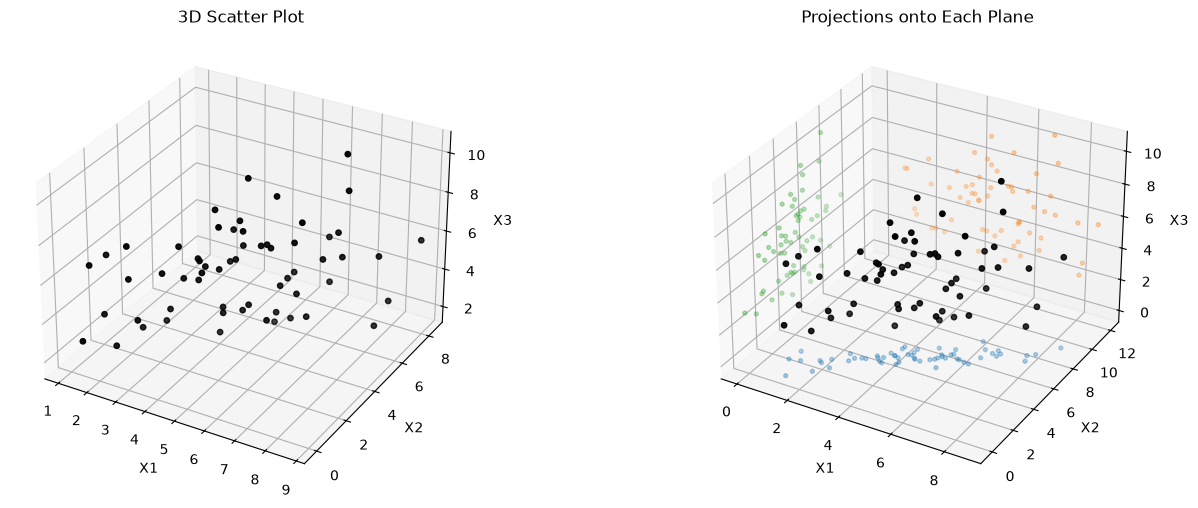

In [3]:
# Figures 10.1 and 10.3: 3D scatter plot and projections onto each plane
fig = plt.figure(figsize=(16, 6))

ax = fig.add_subplot(1, 2, 1, projection='3d')
ax.scatter(x1, x2, x3, color='black', s=15)
ax.set_title('3D Scatter Plot')

ax = fig.add_subplot(1, 2, 2, projection='3d')
ax.scatter(x1, x2, x3, color='black', s=15)
ax.scatter(x1, x2, np.full(n, 0), color='C0', s=8, alpha=0.6)    # Projection onto X1-X2 plane
ax.scatter(x1, np.full(n, 12), x3, color='C1', s=8, alpha=0.6)   # Projection onto X1-X3 plane
ax.scatter(np.full(n, 0), x2, x3, color='C2', s=8, alpha=0.6)    # Projection onto X2-X3 plane
ax.set_title('Projections onto Each Plane')

for axis in fig.axes:
    axis.set_xlabel('X1')
    axis.set_ylabel('X2')
    axis.set_zlabel('X3')

# Display the chart
plt.show()

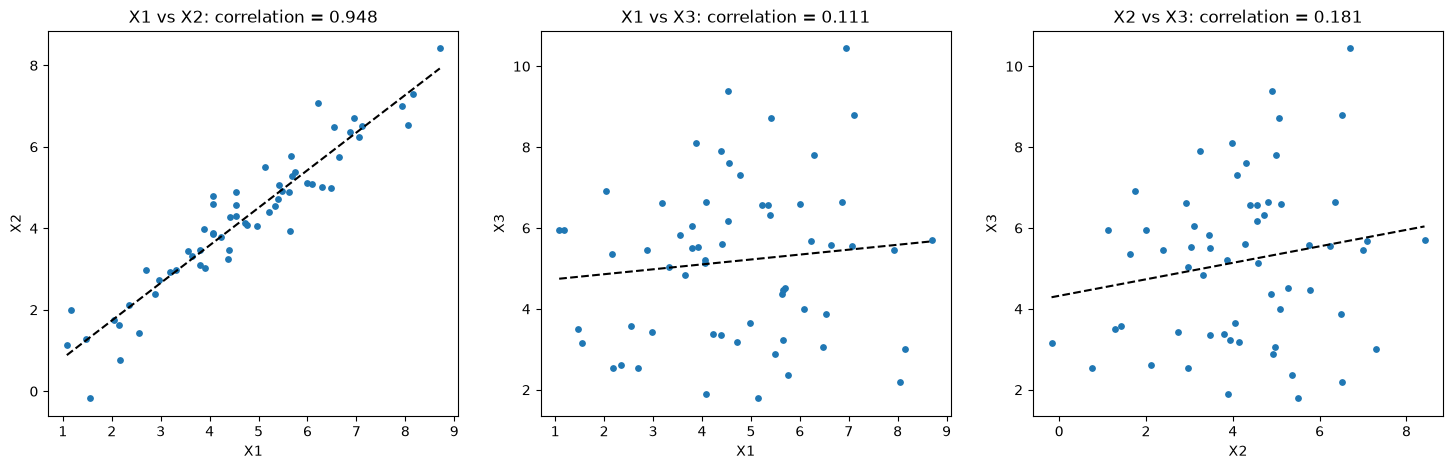

In [4]:
# Figure 10.2: projection of points onto each plane, with dashed linear fit
fig, ax = plt.subplots(1, 3, figsize=(18, 5))

for axis, (a, b) in zip(ax, [("X1", "X2"), ("X1", "X3"), ("X2", "X3")]):
    axis.scatter(hypothetical[a], hypothetical[b], s=15)
    slope, intercept = np.polyfit(hypothetical[a], hypothetical[b], 1)
    xs = np.linspace(hypothetical[a].min(), hypothetical[a].max(), 10)
    axis.plot(xs, intercept + slope * xs, 'k--')
    axis.set_xlabel(a)
    axis.set_ylabel(b)
    axis.set_title(f'{a} vs {b}: correlation = {np.round(hypothetical[a].corr(hypothetical[b]), 3)}')

# Display the chart
plt.show()

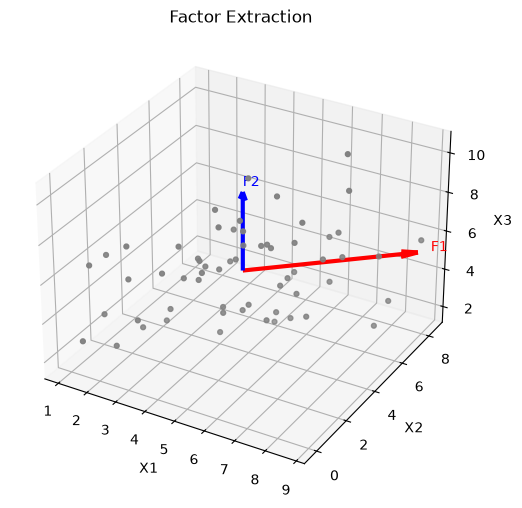

In [5]:
# Figure 10.4: extraction of factors F1 (common direction of X1 and X2) and F2 (direction of X3)
fig = plt.figure(figsize=(8, 6))
ax = fig.add_subplot(projection='3d')
ax.scatter(x1, x2, x3, color='gray', s=12)

center = hypothetical.mean().values
ax.quiver(*center, 4, 4, 0, color='red', linewidth=3, arrow_length_ratio=0.1)
ax.quiver(*center, 0, 0, 4, color='blue', linewidth=3, arrow_length_ratio=0.1)
ax.text(*(center + [4.3, 4.3, 0]), 'F1', color='red')
ax.text(*(center + [0, 0, 4.3]), 'F2', color='blue')

ax.set_xlabel('X1')
ax.set_ylabel('X2')
ax.set_zlabel('X3')
ax.set_title('Factor Extraction')

# Display the chart
plt.show()

Notice that $X_1$ and $X_2$ can be well represented by a single factor $F_1$, whereas $X_3$ requires another factor $F_2$, orthogonal to $F_1$. Factors are therefore latent dimensions that explain the behavior of the original variables.

## **Example: Finance, Cost Accounting, Marketing, and Actuarial Science Grades**

A professor collected the final grades (0 to 10) of 100 students in Finance, Cost Accounting, Marketing, and Actuarial Science and wants to study the joint behavior of the grades to build a performance ranking.

The textbook presents the correlation matrix computed from the 100 students (Table 10.6), and the entire factor analysis starts from it.

In [6]:
variables = ["finance", "cost_accounting", "marketing", "actuarial"]

rho = pd.DataFrame([[1.000, 0.756, -0.030, 0.711],
                    [0.756, 1.000, 0.003, 0.809],
                    [-0.030, 0.003, 1.000, -0.044],
                    [0.711, 0.809, -0.044, 1.000]],
                   index=variables, columns=variables)

n_students = 100
k = len(variables)

print(f"Determinant of the correlation matrix: {np.round(np.linalg.det(rho), 3)}")
rho

Determinant of the correlation matrix: 0.137


,finance,cost_accounting,marketing,actuarial
finance,1.000,0.756,-0.030,0.711
cost_accounting,0.756,1.000,0.003,0.809
marketing,-0.030,0.003,1.000,-0.044
actuarial,0.711,0.809,-0.044,1.000


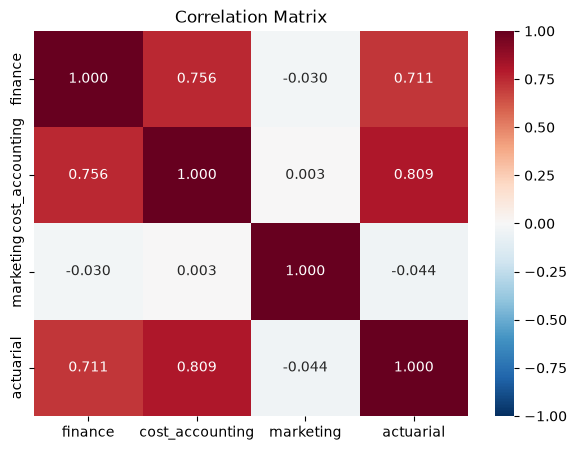

In [7]:
plt.figure(figsize=(7, 5))
sns.heatmap(rho, annot=True, cmap='RdBu_r', vmin=-1, vmax=1, fmt='.3f')
plt.title('Correlation Matrix')

# Display the chart
plt.show()

Notice that finance, cost accounting, and actuarial science have high correlations with one another (0.756, 0.711, and 0.809), while marketing has virtually no relationship with the others. This is a first indication that finance, cost accounting, and actuarial science will form one factor and marketing another.

## **Overall Adequacy of Factor Analysis**

Before extracting factors, we check whether the correlations are high and significant enough.

### **KMO (Kaiser-Meyer-Olkin) Statistic**

Measures the proportion of common variance across all variables by comparing Pearson correlations $\rho$ with partial correlations $\varphi$:

$KMO = \frac{\sum_{l}\sum_{c}\rho_{lc}^2}{\sum_{l}\sum_{c}\rho_{lc}^2 + \sum_{l}\sum_{c}\varphi_{lc}^2}, \quad l \neq c$

`Partial correlation` measures the correlation between two variables while controlling for the effect of the others. With three variables, the first-order partial correlation is:

$\varphi_{ab,c} = \frac{\rho_{ab} - \rho_{ac}\cdot\rho_{bc}}{\sqrt{(1-\rho_{ac}^2)\cdot(1-\rho_{bc}^2)}}$

and with four variables, the second-order partial correlation is:

$\varphi_{ab,cd} = \frac{\varphi_{ab,c} - \varphi_{ad,c}\cdot\varphi_{bd,c}}{\sqrt{(1-\varphi_{ad,c}^2)\cdot(1-\varphi_{bd,c}^2)}}$

| KMO | Overall Adequacy |
|---|---|
| Between 0.90 and 1.00 | Very good (Marvelous) |
| Between 0.80 and 0.90 | Good (Meritorious) |
| Between 0.70 and 0.80 | Average (Middling) |
| Between 0.60 and 0.70 | Fair (Mediocre) |
| Between 0.50 and 0.60 | Poor (Miserable) |
| Below 0.50 | Unacceptable |

In [8]:
def first_order_correlation(r, a, b, c):
    return (r.loc[a, b] - r.loc[a, c] * r.loc[b, c]) / np.sqrt((1 - r.loc[a, c]**2) * (1 - r.loc[b, c]**2))

def second_order_correlation(r, a, b, c, d):
    ab_c = first_order_correlation(r, a, b, c)
    ad_c = first_order_correlation(r, a, d, c)
    bd_c = first_order_correlation(r, b, d, c)
    return (ab_c - ad_c * bd_c) / np.sqrt((1 - ad_c**2) * (1 - bd_c**2))

# Example: finance and cost accounting, controlling for marketing and actuarial science
print(f"First-order (controlling for marketing): {np.round(first_order_correlation(rho, 'finance', 'cost_accounting', 'marketing'), 3)}")
print(f"Second-order (controlling for marketing and actuarial): {np.round(second_order_correlation(rho, 'finance', 'cost_accounting', 'marketing', 'actuarial'), 3)}")

First-order (controlling for marketing): 0.756
Second-order (controlling for marketing and actuarial): 0.438


With many variables, recursive calculation becomes cumbersome. In practice, partial correlations of all orders are obtained directly from the inverse of the correlation matrix: $\varphi_{lc} = -\frac{\rho^{-1}_{lc}}{\sqrt{\rho^{-1}_{ll}\cdot\rho^{-1}_{cc}}}$.

In [9]:
def partial_correlation_matrix(r):
    inverse = np.linalg.inv(r)
    d = np.sqrt(np.diag(inverse))
    partial = -inverse / np.outer(d, d)
    np.fill_diagonal(partial, 1)
    return pd.DataFrame(partial, index=r.index, columns=r.columns)

def kmo(r):
    partial = partial_correlation_matrix(r).values
    off_diagonal = ~np.eye(len(r), dtype=bool)
    sum_r2 = np.sum(r.values[off_diagonal]**2)
    sum_p2 = np.sum(partial[off_diagonal]**2)
    return sum_r2 / (sum_r2 + sum_p2)

print(f"KMO: {np.round(kmo(rho), 3)}")
partial_correlation_matrix(rho).round(3)

KMO: 0.737


,finance,cost_accounting,marketing,actuarial
finance,1.000,0.438,-0.030,0.256
cost_accounting,0.438,1.000,0.072,0.592
marketing,-0.030,0.072,1.000,-0.069
actuarial,0.256,0.592,-0.069,1.000


Notice that the KMO is 0.737, so the overall adequacy of the factor analysis is `average (middling)`. The partial correlations match Table 10.8 of the textbook (0.438 between finance and cost accounting, 0.592 between cost accounting and actuarial science, etc.).

### **Bartlett's Test of Sphericity**

Compares the correlation matrix with the identity matrix $I$:

$H_0: \rho = I$ (the variables are uncorrelated and there are no factors to extract)

$H_1: \rho \neq I$

$\chi^2_{Bartlett} = -\left[(n-1) - \frac{2\cdot k+5}{6}\right]\cdot\ln|D| \sim \chi^2_{k(k-1)/2}$

where $D$ is the determinant of the correlation matrix.

`NOTE:` *The textbook recommends deciding based on Bartlett's test rather than KMO, because the test has a formal significance level. With only two variables, for example, KMO is always 0.50.*

In [10]:
def bartlett_sphericity(r, n):
    k = len(r)
    statistic = -((n - 1) - (2 * k + 5) / 6) * np.log(np.linalg.det(r))
    df = k * (k - 1) / 2
    return statistic, df, chi2.sf(statistic, df)

chi2_bartlett, df_bartlett, p_bartlett = bartlett_sphericity(rho, n_students)

print(f"Bartlett's Chi-square: {np.round(chi2_bartlett, 3)} ({int(df_bartlett)} df)")
print(f"Critical Chi-square (5%): {np.round(chi2.ppf(0.95, df_bartlett), 3)}")
print(f"P-value: {p_bartlett:.2e}")

Bartlett's Chi-square: 192.358 (6 df)
Critical Chi-square (5%): 12.592
P-value: 8.02e-39


Notice that $\chi^2_{Bartlett} = 192.358$ is much greater than $\chi^2_c = 12.592$ (p-value on the order of $10^{-39}$), so we reject $H_0$: the correlation matrix differs from the identity matrix, and factor analysis is appropriate. The textbook arrives at 192.335, with the slight difference due to rounding the determinant (0.137).

## **Factor Extraction via Principal Components**

Factors are linear combinations of the standardized variables:

$F_{1i} = s_{11}\cdot ZX_{1i} + s_{21}\cdot ZX_{2i} + \cdots + s_{k1}\cdot ZX_{ki}$

$\vdots$

$F_{ki} = s_{1k}\cdot ZX_{1i} + s_{2k}\cdot ZX_{2i} + \cdots + s_{kk}\cdot ZX_{ki}$

The coefficients $s$ are the `factor scores` (scoring coefficients), obtained from the eigenvalues $\lambda^2$ and eigenvectors $v$ of the correlation matrix:

$\det(\lambda^2\cdot I - \rho) = 0, \quad \lambda_1^2 \geq \lambda_2^2 \geq \cdots \geq \lambda_k^2, \quad \sum_{j=1}^{k}\lambda_j^2 = k$

$s_{lj} = \frac{v_{lj}}{\sqrt{\lambda_j^2}}$

* `Latent root criterion (Kaiser):` we retain only factors with eigenvalues greater than 1, because a factor with an eigenvalue below 1 accounts for less variance than a single original variable.
* Each eigenvalue divided by $k$ represents the share of total variance explained by that factor.

In [11]:
eigenvalues, eigenvectors = np.linalg.eigh(rho)

# Sort from largest to smallest eigenvalue
order = np.argsort(eigenvalues)[::-1]
eigenvalues = eigenvalues[order]
eigenvectors = eigenvectors[:, order]

# Sign convention: positive finance coefficient in each eigenvector (as in the textbook)
eigenvectors = eigenvectors * np.sign(eigenvectors[0, :])

factors = [f"F{j+1}" for j in range(k)]
print(f"Sum of eigenvalues: {np.round(eigenvalues.sum(), 3)}")

pd.DataFrame(eigenvectors, index=variables, columns=factors).round(4)

Sum of eigenvalues: 4.0


,F1,F2,F3,F4
finance,0.5642,0.0064,0.8006,0.2019
cost_accounting,0.5887,0.0487,-0.2194,-0.7765
marketing,-0.0267,0.9987,0.0002,0.0423
actuarial,0.5783,-0.0096,-0.5576,0.5954


In [12]:
# Shared variance explained by each factor (Table 10.9)
variance = pd.DataFrame({
    "Eigenvalue": eigenvalues,
    "Shared Variance (%)": eigenvalues / k * 100,
    "Cumulative Variance (%)": np.cumsum(eigenvalues) / k * 100
}, index=factors)
variance.round(3)

,Eigenvalue,Shared Variance (%),Cumulative Variance (%)
F1,2.519,62.978,62.978
F2,1.000,25.009,87.988
F3,0.298,7.439,95.427
F4,0.183,4.573,100.000


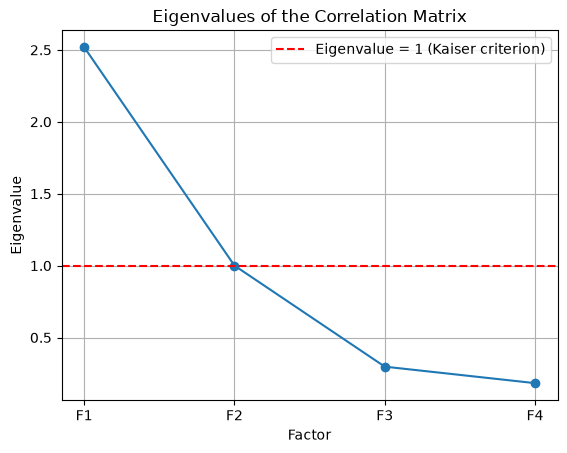

In [13]:
# Eigenvalues chart (scree plot) with Kaiser criterion
plt.plot(range(1, k + 1), eigenvalues, 'o-')
plt.axhline(1, color='red', linestyle='--', label='Eigenvalue = 1 (Kaiser criterion)')
plt.xticks(range(1, k + 1), factors)
plt.xlabel('Factor')
plt.ylabel('Eigenvalue')
plt.title('Eigenvalues of the Correlation Matrix')
plt.legend()
plt.grid(True)

# Display the chart
plt.show()

Notice that the eigenvalues are 2.519, 1.000, 0.298, and 0.183, matching the textbook. By the Kaiser criterion, we retain the first two factors, which together explain 87.985% of the total variance—meaning we lose 12.015% of the variance of the original variables.

`NOTE:` *The second eigenvalue is exactly 1.000, right on the threshold of the criterion. The textbook retains this factor, which, as we will see, is essentially the marketing grade itself.*

In [14]:
# Verifying the relation V' . rho . V = diagonal matrix of eigenvalues
(eigenvectors.T @ rho.values @ eigenvectors).round(3)

array([[ 2.519, -0.   , -0.   ,  0.   ],
       [-0.   ,  1.   , -0.   ,  0.   ],
       [-0.   , -0.   ,  0.298, -0.   ],
       [ 0.   ,  0.   , -0.   ,  0.183]])

In [15]:
# Factor score coefficients
factor_scores = pd.DataFrame(eigenvectors / np.sqrt(eigenvalues), index=variables, columns=factors)
factor_scores.round(3)

,F1,F2,F3,F4
finance,0.355,0.006,1.468,0.472
cost_accounting,0.371,0.049,-0.402,-1.815
marketing,-0.017,0.999,0.000,0.099
actuarial,0.364,-0.010,-1.022,1.392


Using the factor score coefficients, the factors are:

$F_{1i} = 0.355\cdot Z\text{finance}_i + 0.371\cdot Z\text{cost\_accounting}_i - 0.017\cdot Z\text{marketing}_i + 0.364\cdot Z\text{actuarial}_i$

$F_{2i} = 0.007\cdot Z\text{finance}_i + 0.049\cdot Z\text{cost\_accounting}_i + 0.999\cdot Z\text{marketing}_i - 0.010\cdot Z\text{actuarial}_i$

and so on. Let's verify using the standardized grades of the students shown in Table 10.10 of the textbook:

In [16]:
z_textbook = pd.DataFrame({
    "finance": [-0.011, -0.876, -0.876, 1.334, -0.779, 1.334, -0.267, -0.139, 0.021, 0.982],
    "cost_accounting": [-0.290, -0.697, -0.290, 1.337, -1.104, 2.150, 0.116, 0.523, -0.290, 0.113],
    "marketing": [-1.650, 1.532, -0.590, 0.825, -0.872, -1.650, 0.825, 0.118, -0.590, -1.297],
    "actuarial": [0.273, -1.319, -0.523, 1.069, -0.841, 1.865, -0.125, 0.273, -0.523, 1.069]
}, index=["Gabriela", "Luiz Felipe", "Patrícia", "Gustavo", "Letícia",
          "Ovídio", "Leonor", "Dalila", "Antônio", "Estela"])

(z_textbook @ factor_scores).round(3)

,F1,F2,F3,F4
Gabriela,0.016,-1.664,-0.179,0.738
Luiz Felipe,-1.076,1.503,0.344,-0.833
Patrícia,-0.600,-0.604,-0.635,-0.673
Gustavo,1.346,0.887,0.328,-0.228
Letícia,-0.978,-0.921,0.160,0.380
Ovídio,1.979,-1.552,-0.814,-0.841
Leonor,-0.111,0.829,-0.310,-0.429
Dalila,0.242,0.140,-0.693,-0.623
Antônio,-0.281,-0.598,0.682,-0.250
Estela,0.802,-1.294,0.303,1.618


Notice that the factor values match Table 10.10 of the textbook (for example, $F_1 = 0.016$ and $F_2 = -1.665$ for Gabriela).

## **Factor Loadings and Communalities**

* `Factor loadings:` the Pearson correlations between each variable and each factor, $c_{lj} = v_{lj}\cdot\sqrt{\lambda_j^2}$. The sum of squared loadings in a column equals the eigenvalue of that factor.
* `Communality:` the sum of squared loadings of a variable across the extracted factors. It represents the proportion of the variable's variance shared with those factors; very low communalities suggest removing the variable from the analysis.

$c_{11}^2 + c_{12}^2 + \cdots = \text{communality}_{X_1}$

In [17]:
loadings = pd.DataFrame(eigenvectors * np.sqrt(eigenvalues), index=variables, columns=factors)

print("Sum of squared loadings in each column (eigenvalues):")
print((loadings**2).sum().round(3).to_dict())
loadings.round(3)

Sum of squared loadings in each column (eigenvalues):
{'F1': 2.519, 'F2': 1.0, 'F3': 0.298, 'F4': 0.183}


,F1,F2,F3,F4
finance,0.895,0.006,0.437,0.086
cost_accounting,0.934,0.049,-0.120,-0.332
marketing,-0.042,0.999,0.000,0.018
actuarial,0.918,-0.010,-0.304,0.255


In [18]:
# Communalities considering the two extracted factors
extracted_factors = ["F1", "F2"]
communalities = (loadings[extracted_factors]**2).sum(axis=1)
communalities.round(3)

finance            0.802
cost_accounting    0.875
marketing          1.000
actuarial          0.843
dtype: float64

Notice that finance, cost accounting, and actuarial science have high loadings on the first factor (0.895, 0.934, and 0.918), while marketing has a high loading only on the second (0.999). Based on communalities, marketing loses virtually no variance with the two factors (1.000), while finance loses the most (around 19.8%).

`NOTE:` *Factor loadings are the regression coefficients of a standardized variable on the factors, and the $R^2$ of that regression is the communality. Factor score coefficients, in turn, are the regression coefficients of a factor on the standardized variables.*

### **Loading Plot**

The `loading plot` positions each variable using its loadings as coordinates on the plane formed by the factors.

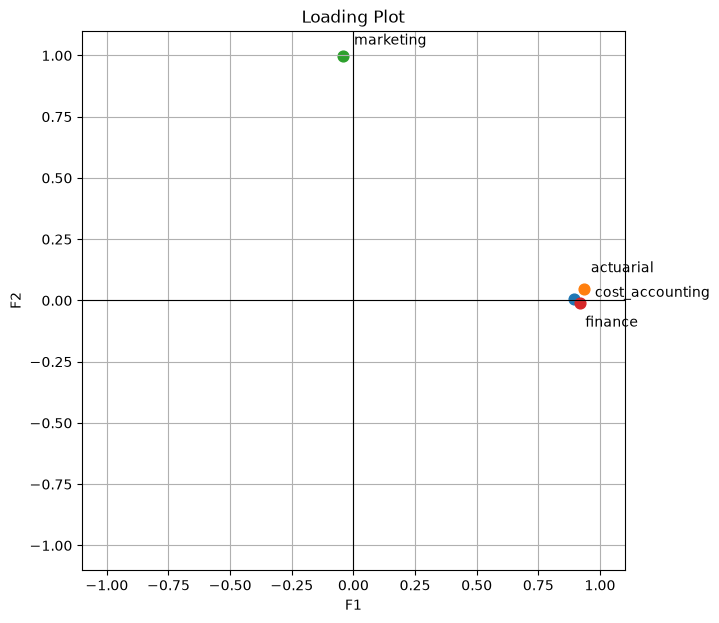

In [19]:
def loading_plot(loadings, title, axes=("F1", "F2")):

    fig, ax = plt.subplots(figsize=(7, 7))
    ax.axhline(0, color='black', linewidth=0.8)
    ax.axvline(0, color='black', linewidth=0.8)

    for i, (variable, row) in enumerate(loadings.iterrows()):
        ax.scatter(row[axes[0]], row[axes[1]], s=60)
        # Offset labels to avoid overlap when loadings are similar
        ax.annotate(variable, (row[axes[0]], row[axes[1]]), xytext=(8, 14 * i - 20),
                    textcoords='offset points', fontsize=10)

    ax.set_xlim(-1.1, 1.1)
    ax.set_ylim(-1.1, 1.1)
    ax.set_xlabel(axes[0])
    ax.set_ylabel(axes[1])
    ax.set_title(title)
    ax.grid(True)

    # Display the chart
    plt.show()

# Figure 10.8: loading plot
loading_plot(loadings, 'Loading Plot')

Notice that finance, cost accounting, and actuarial science cluster together near the first factor's axis, while marketing sits alone on the second axis. One possible interpretation is that Finance, Cost Accounting, and Actuarial Science are more quantitative subjects, whereas Marketing is more qualitative and behavioral.

`NOTE:` *Factor analysis does not require naming the factors. Doing so demands deep domain knowledge of the phenomenon being studied.*

## **Factor Rotation**

When some variables have intermediate loadings across all factors, we can `rotate` the factors around the origin to increase each variable's loading on one factor and decrease it on the others, making interpretation easier. Consider the idea with a hypothetical scenario, as in Figures 10.5 and 10.6 of the textbook:

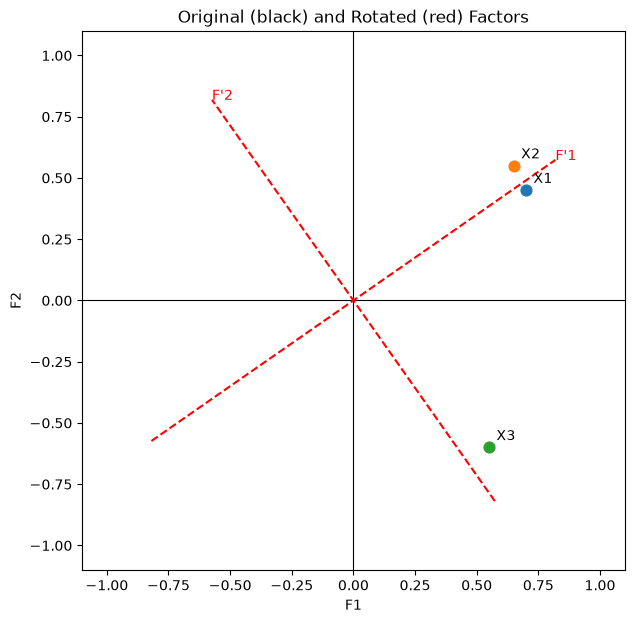

In [20]:
# Figures 10.5 and 10.6: hypothetical loading plot and rotated factors
hypothetical_loadings = pd.DataFrame({"F1": [0.70, 0.65, 0.55], "F2": [0.45, 0.55, -0.60]}, index=["X1", "X2", "X3"])
angle = np.radians(35)

fig, ax = plt.subplots(figsize=(7, 7))
ax.axhline(0, color='black', linewidth=0.8)
ax.axvline(0, color='black', linewidth=0.8)

# Axes of the rotated factors F'1 and F'2
for (dx, dy), name in [((np.cos(angle), np.sin(angle)), "F'1"), ((-np.sin(angle), np.cos(angle)), "F'2")]:
    ax.plot([-dx, dx], [-dy, dy], 'r--')
    ax.text(dx, dy, name, color='red')

for variable, row in hypothetical_loadings.iterrows():
    ax.scatter(row["F1"], row["F2"], s=60)
    ax.text(row["F1"] + 0.03, row["F2"] + 0.03, variable)

ax.set_xlim(-1.1, 1.1)
ax.set_ylim(-1.1, 1.1)
ax.set_xlabel('F1')
ax.set_ylabel('F2')
ax.set_title('Original (black) and Rotated (red) Factors')

# Display the chart
plt.show()

Notice that by rotating the axes, X1 and X2 move closer to $F'_1$ and X3 moves closer to $F'_2$.

Rotation does not change the communalities, total explained variance, KMO, or Bartlett's test, but it `redistributes` variance among the factors, producing new eigenvalues.

### **Varimax Rotation**

The most widely used orthogonal rotation (Kaiser, 1958). For a pair of factors, the rotated loadings are:

$\begin{bmatrix} c'_{11} & c'_{12} \\ \vdots & \vdots \\ c'_{k1} & c'_{k2} \end{bmatrix} = \begin{bmatrix} c_{11} & c_{12} \\ \vdots & \vdots \\ c_{k1} & c_{k2} \end{bmatrix}\cdot\begin{bmatrix} \cos\theta & -\sin\theta \\ \sin\theta & \cos\theta \end{bmatrix}$

with rotation angle

$\theta = 0.25\cdot\arctan\left[\frac{2\cdot(D\cdot k - A\cdot B)}{C\cdot k - (A^2 - B^2)}\right]$

where, with $h_l = \text{communality}_l$:

$A = \sum_{l=1}^{k}\left(\frac{c_{l1}^2}{h_l} - \frac{c_{l2}^2}{h_l}\right) \quad B = \sum_{l=1}^{k}\left(2\cdot\frac{c_{l1}\cdot c_{l2}}{h_l}\right)$

$C = \sum_{l=1}^{k}\left[\left(\frac{c_{l1}^2}{h_l} - \frac{c_{l2}^2}{h_l}\right)^2 - \left(2\cdot\frac{c_{l1}\cdot c_{l2}}{h_l}\right)^2\right] \quad D = \sum_{l=1}^{k}\left[\left(\frac{c_{l1}^2}{h_l} - \frac{c_{l2}^2}{h_l}\right)\cdot\left(2\cdot\frac{c_{l1}\cdot c_{l2}}{h_l}\right)\right]$

`NOTE:` *Other orthogonal rotations include Quartimax and Equimax. Oblique rotations (Direct Oblimin and Promax) produce correlated factors.*

In [21]:
def varimax_two_factors(loadings):

    c1, c2 = loadings.iloc[:, 0].values, loadings.iloc[:, 1].values
    h = c1**2 + c2**2  # Communalities
    k = len(c1)

    u = c1**2 / h - c2**2 / h
    v = 2 * c1 * c2 / h
    A, B = u.sum(), v.sum()
    C = np.sum(u**2 - v**2)
    D = np.sum(u * v)

    theta = 0.25 * np.arctan2(2 * (D * k - A * B), C * k - (A**2 - B**2))
    rotation = np.array([[np.cos(theta), -np.sin(theta)],
                         [np.sin(theta), np.cos(theta)]])

    print(f"A = {np.round(A, 3)} | B = {np.round(B, 3)} | C = {np.round(C, 3)} | D = {np.round(D, 3)}")
    print(f"Rotation angle: {np.round(theta, 3)} rad")

    rotated = pd.DataFrame(loadings.values @ rotation, index=loadings.index, columns=["F'1", "F'2"])
    return rotated, rotation

rotated_loadings, rotation_matrix = varimax_two_factors(loadings[extracted_factors])
rotated_loadings.round(3)

A = 1.998 | B = 0.012 | C = 3.963 | D = 0.181
Rotation angle: 0.029 rad


,F'1,F'2
finance,0.895,-0.020
cost_accounting,0.935,0.021
marketing,-0.013,1.000
actuarial,0.917,-0.037


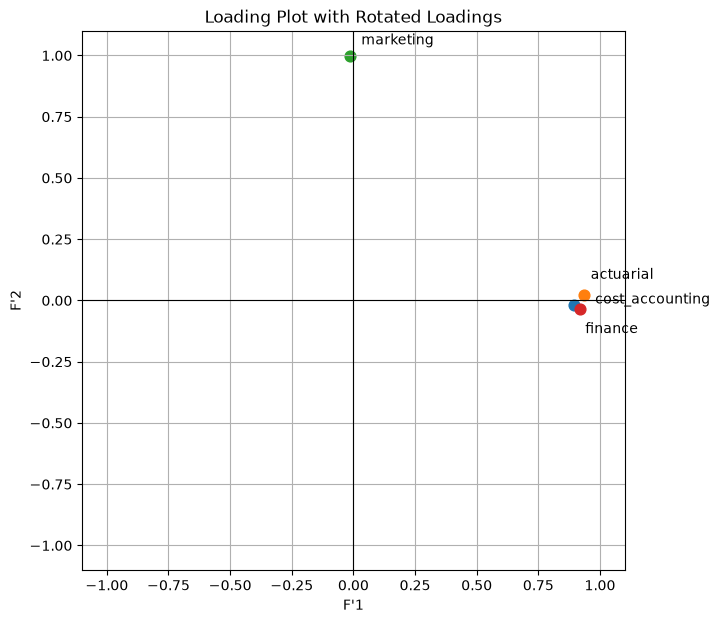

In [22]:
# Figure 10.9: loading plot with rotated loadings
loading_plot(rotated_loadings, 'Loading Plot with Rotated Loadings', axes=("F'1", "F'2"))

In [23]:
# Rotation does not change communalities, but redistributes eigenvalues (Table 10.17)
print("Communalities:", (rotated_loadings**2).sum(axis=1).round(3).to_dict())

rotated_eigenvalues = (rotated_loadings**2).sum()
pd.DataFrame({"Eigenvalue": rotated_eigenvalues,
              "Shared Variance (%)": rotated_eigenvalues / k * 100,
              "Cumulative Variance (%)": np.cumsum(rotated_eigenvalues) / k * 100}).round(3)

Communalities: {'finance': 0.802, 'cost_accounting': 0.875, 'marketing': 1.0, 'actuarial': 0.843}


,Eigenvalue,Shared Variance (%),Cumulative Variance (%)
F'1,2.518,62.945,62.945
F'2,1.002,25.042,87.988


Notice that the rotation angle is small (0.029 rad) because the loading plot was already very clear, so the loadings barely change. The eigenvalues shift from 2.519 and 1.000 to 2.518 and 1.002, and the total shared variance remains 87.988%. Rotation only redistributed variance between the factors.

In [24]:
# Rotated factor score coefficients: F' = Z . S . R
rotated_scores = pd.DataFrame(factor_scores[extracted_factors].values @ rotation_matrix,
                              index=variables, columns=["F'1", "F'2"])
rotated_scores.round(3)

,F'1,F'2
finance,0.355,-0.004
cost_accounting,0.372,0.038
marketing,0.012,0.999
actuarial,0.364,-0.020


Thus, the rotated factors are:

$F'_{1i} = 0.355\cdot Z\text{finance}_i + 0.372\cdot Z\text{cost\_accounting}_i + 0.012\cdot Z\text{marketing}_i + 0.364\cdot Z\text{actuarial}_i$

$F'_{2i} = -0.004\cdot Z\text{finance}_i + 0.038\cdot Z\text{cost\_accounting}_i + 0.999\cdot Z\text{marketing}_i - 0.021\cdot Z\text{actuarial}_i$

## **Performance Ranking**

A well-accepted criterion for building rankings from factors is `weighted sum and ordering`: we sum the values of the factors with eigenvalues greater than 1, weighted by each factor's shared variance, and rank the observations. This accounts for performance across all variables, not just the primary factor.

$\text{Performance}_i = F'_{1i}\cdot 0.62942 + F'_{2i}\cdot 0.25043$

First, let's verify with the students shown in Table 10.18 of the textbook:

In [25]:
z_ranking_textbook = pd.DataFrame({
    "finance": [1.30, 0.60, 1.33, 1.33, -1.29, -0.88, -0.01, 0.50, -1.64, -1.52],
    "cost_accounting": [2.15, 2.15, 2.15, 2.07, -0.55, -0.70, -0.29, -0.50, -1.16, -1.16],
    "marketing": [1.53, 1.53, -1.65, -1.65, 1.53, 1.53, -1.65, -0.94, -1.01, -1.40],
    "actuarial": [1.86, 1.86, 1.86, 1.86, -1.04, -1.32, 0.27, -1.16, -1.00, -1.44]
}, index=["Adelino", "Renata", "Ovídio", "Kamal", "Itamar", "Luiz Felipe",
          "Gabriela", "Marina", "Viviane", "Gilmar"])

weights = rotated_eigenvalues.values / k

ranking_textbook = z_ranking_textbook @ rotated_scores
ranking_textbook["Performance"] = ranking_textbook.values @ weights
ranking_textbook.round(3)

,F'1,F'2,Performance
Adelino,1.958,1.566,1.625
Renata,1.709,1.569,1.469
Ovídio,1.929,-1.610,0.811
Kamal,1.899,-1.613,0.792
Itamar,-1.023,1.533,-0.260
Luiz Felipe,-1.035,1.532,-0.268
Gabriela,-0.034,-1.664,-0.438
Marina,-0.442,-0.936,-0.513
Viviane,-1.391,-1.025,-1.133
Gilmar,-1.514,-1.406,-1.305


Notice that the values match Table 10.18 (Adelino: $F'_1 = 1.959$, $F'_2 = 1.568$, and performance 1.626).

The textbook does not include the full grades of all 100 students (the complete dataset is in the publisher's `NotasFatorial.xls` file). To build the full ranking, let's simulate 100 students with `exactly` the same correlation matrix as the textbook.

In [26]:
np.random.seed(42)

# Generating data with the exact correlation matrix from the textbook
z = np.random.normal(size=(n_students, k))
z = (z - z.mean(axis=0)) @ np.linalg.inv(np.linalg.cholesky(np.cov(z, rowvar=False)).T)
z = z @ np.linalg.cholesky(rho.values).T

student_grades = pd.DataFrame(np.clip(6 + 1.5 * z, 0, 10), columns=variables)
student_grades.index = [f"Student {i+1}" for i in range(n_students)]

print(f"Largest difference relative to textbook correlations: {np.round(np.abs(student_grades.corr() - rho).values.max(), 4)}")
student_grades.describe().round(2)

Largest difference relative to textbook correlations: 0.007


,finance,cost_accounting,marketing,actuarial
count,100.00,100.00,100.00,100.00
mean,6.00,5.99,6.00,6.00
std,1.50,1.48,1.50,1.50
min,2.52,3.19,1.38,3.26
25%,4.78,4.88,5.18,4.84
50%,6.02,5.79,6.07,5.92
75%,6.93,6.96,7.03,7.09
max,10.00,10.00,9.06,9.62


In [27]:
# Standardization (Z-scores), rotated factors, and ranking
z_students = (student_grades - student_grades.mean()) / student_grades.std()

ranking = z_students @ rotated_scores
ranking["Performance"] = ranking.values @ weights
ranking["Rank"] = ranking["Performance"].rank(ascending=False).astype(int)
ranking = ranking.sort_values("Rank")

print("Correlation between rotated factors:", np.round(ranking["F'1"].corr(ranking["F'2"]), 3))
pd.concat([ranking.head(5), ranking.tail(5)]).round(3)

Correlation between rotated factors: -0.001


,F'1,F'2,Performance,Rank
Student 94,1.730,2.075,1.608,1
Student 53,2.110,0.838,1.538,2
Student 64,2.502,-1.462,1.209,3
Student 42,1.565,0.739,1.170,4
Student 40,2.260,-1.204,1.121,5
Student 12,-1.617,-0.485,-1.139,96
Student 26,-1.828,-0.324,-1.232,97
Student 96,-1.245,-2.072,-1.302,98
Student 60,-1.881,-0.566,-1.326,99
Student 66,-1.238,-3.080,-1.550,100


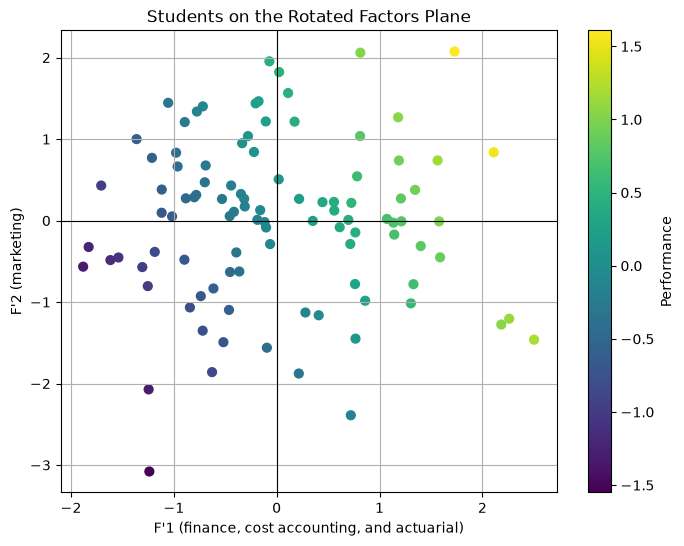

In [28]:
plt.figure(figsize=(8, 6))
plt.scatter(ranking["F'1"], ranking["F'2"], c=ranking["Performance"], cmap='viridis', s=40)
plt.colorbar(label='Performance')
plt.axhline(0, color='black', linewidth=0.8)
plt.axvline(0, color='black', linewidth=0.8)
plt.xlabel("F'1 (finance, cost accounting, and actuarial)")
plt.ylabel("F'2 (marketing)")
plt.title('Students on the Rotated Factors Plane')
plt.grid(True)

# Display the chart
plt.show()

Notice that the rotated factors have 0 correlation with each other (they are orthogonal), and that top-ranked students perform well on both factors.

`NOTE:` *Rankings built from factors are also static: new observations, new variables, or simply the passage of time change the correlation matrix, requiring the analysis to be rerun. Extracted factors can also be used in other techniques, such as cluster analysis or regression.*

## **Appendix: Cronbach's Alpha**

Measures the `internal consistency` of the variables—that is, the reliability with which a single factor can be extracted from them:

$\alpha = \frac{k}{k-1}\cdot\left[1 - \frac{\sum_{k}\text{var}_k}{\text{var}_{\text{sum}}}\right]$

where $\text{var}_k$ is the variance of each variable and $\text{var}_{\text{sum}}$ is the variance of the sum of variables for each observation.

* If the variables are consistent, $\text{var}_{\text{sum}}$ becomes large and $\alpha$ approaches 1.
* Values above 0.6 are generally considered acceptable in exploratory techniques.

`NOTE:` *Cronbach's alpha does not replace KMO and Bartlett's test, because it only evaluates the extraction of a single factor.*

In [29]:
def cronbach_alpha(r):
    # With standardized variables: each variance equals 1 and the variance of the sum is the sum of all elements in r
    k = len(r)
    var_sum = r.values.sum()
    return k / (k - 1) * (1 - k / var_sum)

print(f"Variance of the sum of standardized variables: {np.round(rho.values.sum(), 3)}")
print(f"Cronbach's Alpha: {np.round(cronbach_alpha(rho), 3)}")

Variance of the sum of standardized variables: 8.41
Cronbach's Alpha: 0.699


In [30]:
# Cronbach's Alpha when each variable is dropped
pd.Series({variable: cronbach_alpha(rho.drop(index=variable, columns=variable)) for variable in variables},
          name="Alpha if variable dropped").round(3)

finance            0.508
cost_accounting    0.447
marketing          0.904
actuarial          0.491
Name: Alpha if variable dropped, dtype: float64

Notice that Cronbach's alpha is 0.699, above 0.6. If we drop marketing, it jumps to 0.904, whereas dropping any other variable causes it to plummet. This confirms what factor analysis showed: marketing does not share the same factor as finance, cost accounting, and actuarial science.

## **Factor Analysis Exercises**

### Exercise 1

CRM analysts at a bank performed a factor analysis on age (`age`), percentage invested in fixed income (`fixed_inc`), percentage invested in equities (`equities`), and household size (`household`). The loadings of the two extracted factors were:

In [31]:
loadings_crm = pd.DataFrame({"Factor 1": [0.917, 0.874, -0.844, 0.031],
                             "Factor 2": [0.047, 0.077, 0.197, 0.979]},
                            index=["age", "fixed_inc", "equities", "household"])
loadings_crm

,Factor 1,Factor 2
age,0.917,0.047
fixed_inc,0.874,0.077
equities,-0.844,0.197
household,0.031,0.979


In [32]:
# A) and B) Eigenvalues and shared variance
eigenvalues_crm = (loadings_crm**2).sum()
variance_crm = pd.DataFrame({"Eigenvalue": eigenvalues_crm,
                             "Shared Variance (%)": eigenvalues_crm / 4 * 100})
print(f"Total variance lost: {np.round(100 - variance_crm['Shared Variance (%)'].sum(), 2)}%")
variance_crm.round(3)

Total variance lost: 16.91%


,Eigenvalue,Shared Variance (%)
Factor 1,2.318,57.952
Factor 2,1.005,25.135


In [33]:
# C) Communalities
(loadings_crm**2).sum(axis=1).round(3)

age          0.843
fixed_inc    0.770
equities     0.751
household    0.959
dtype: float64

In [34]:
# D) Each standardized variable as a function of the factors
for variable, row in loadings_crm.iterrows():
    print(f"Z_{variable} = {row['Factor 1']:.3f} * F1 + {row['Factor 2']:.3f} * F2")

Z_age = 0.917 * F1 + 0.047 * F2
Z_fixed_inc = 0.874 * F1 + 0.077 * F2
Z_equities = -0.844 * F1 + 0.197 * F2
Z_household = 0.031 * F1 + 0.979 * F2


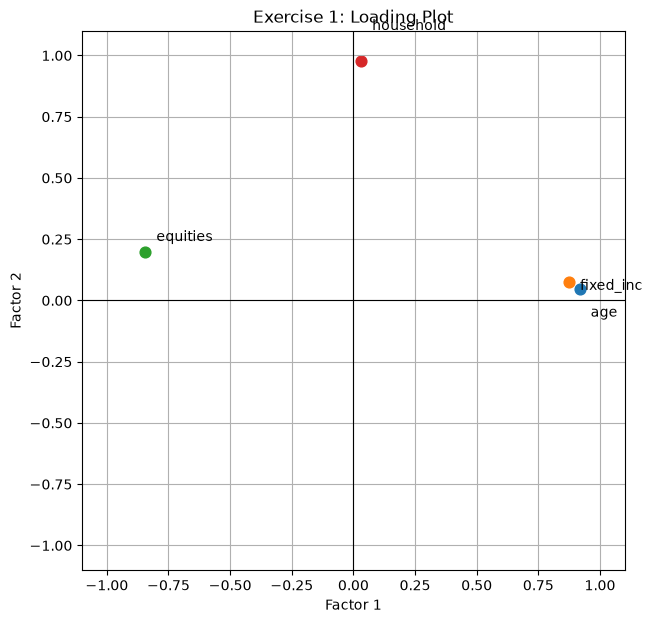

In [35]:
# E) Loading plot
loading_plot(loadings_crm, 'Exercise 1: Loading Plot', axes=("Factor 1", "Factor 2"))

Notice that:
* `Eigenvalues:` 2.318 for Factor 1 (57.95% of variance) and 1.005 for Factor 2 (25.14%), with a total loss of 16.91% of the variance across the four variables.
* `Communalities:` household size (0.959) and age (0.843) are the best represented, while equities (0.751) loses the most variance.
* `Interpretation:` Factor 1 combines age and fixed income with positive signs and equities with a negative sign, representing the `investment profile` (older clients being more conservative). Factor 2 is essentially household size, representing `family size`.

### Exercises 2 and 3

Exercises 2 (`IndicadorPaíses.dta`, indicators for 50 countries across two years) and 3 (`PercepçãoDrogaria.dta`, perceptions of 1,700 customers regarding eight drugstore attributes) use datasets that accompany the textbook and are not included in this repository.

`NOTE:` *To solve them, place the datasets in the `data/` folder and apply the functions from this notebook (`kmo`, `bartlett_sphericity`, eigenvalues via `np.linalg.eigh`, `loading_plot`, and Varimax rotation).*